# Задание 4

Загружаем изображение

In [2]:
import numpy as np
from PIL import Image

im = Image.open('02_lab_data/mushroom_cow_minecraft.jpg').convert('RGB') 
a = np.asarray(im)
print(f"Размер массива: {a.shape}")

Размер массива: (480, 854, 3)


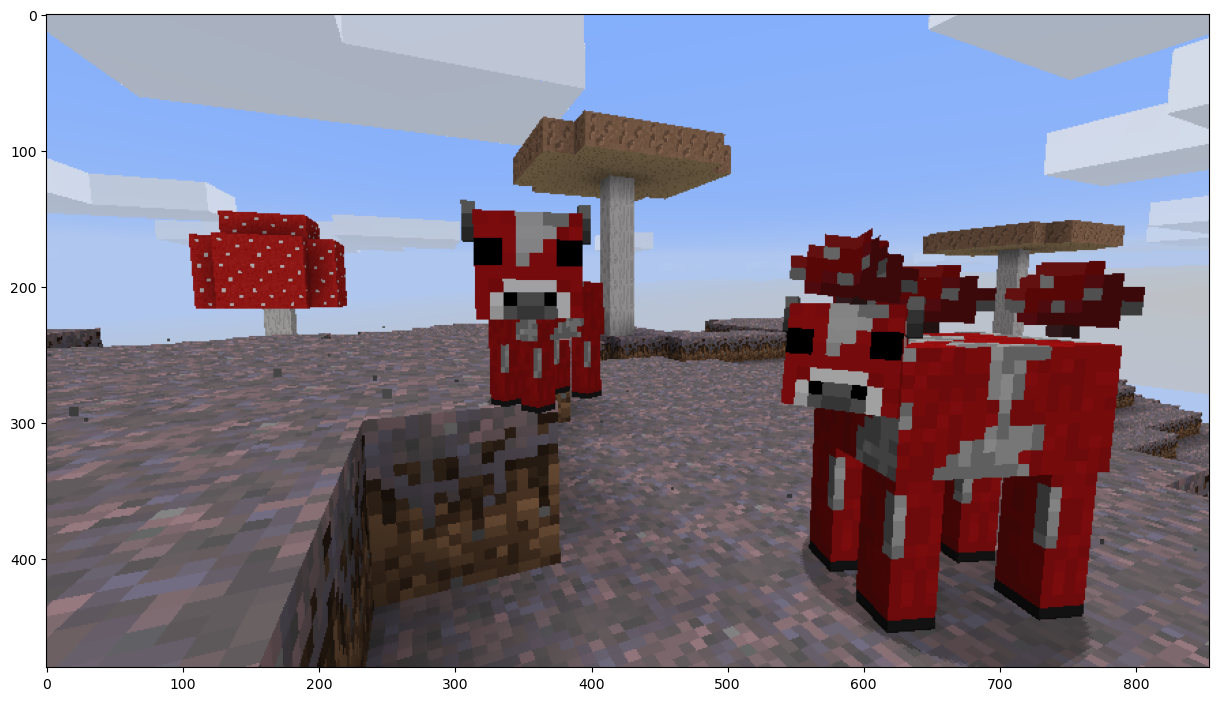

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15.,10.))
plt.imshow(im)

Переводим в трехмерный numpy массив (x, y, цвет).

In [4]:
import numpy as np

a = np.asarray(im)
a[500:505, 495:500]

array([], shape=(0, 5, 3), dtype=uint8)

Найдем фрагменты изображения, с нужным нам наличием/отсутствием цвета.

**Красное:**

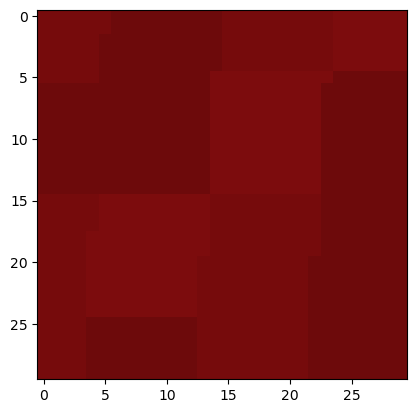

In [5]:
plt.imshow(a[290:320, 640:670])

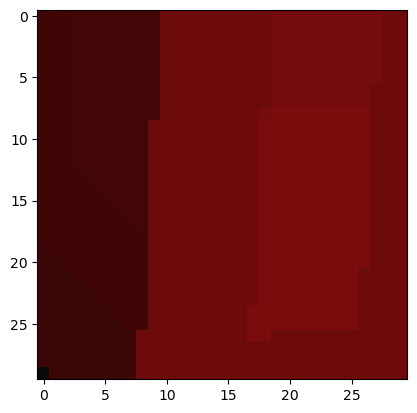

In [6]:
plt.imshow(a[410:440, 610:640])

**Не красное**

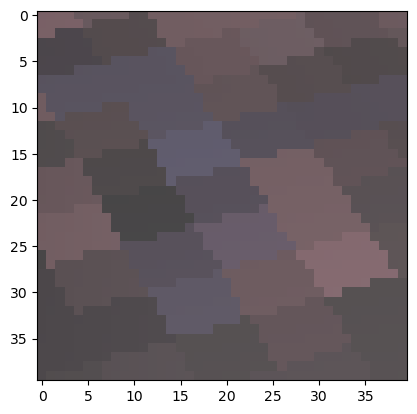

In [7]:
plt.imshow(a[400:440, 380:420])

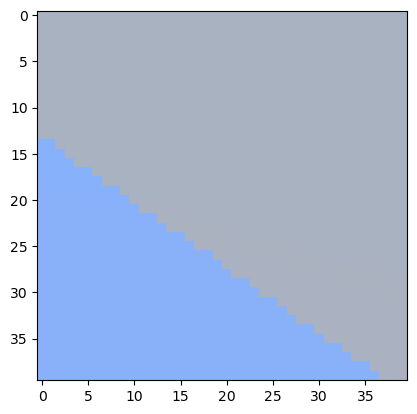

In [8]:
plt.imshow(a[0:40, 0:40])

Подготовка набора данных для обучения.

Желательно, чередовать положительные и отрицательные примеры, при добавлении их в общий массив:

~~y = [0,0,0,1,1,1]~~

`y  = [0,1,0,1,0,1]`.

Должно получиться следующее (*для нейронки с 3-мя входами и одним выходом*):

|x_R|x_G|x_B|y_Target|
|---|---|---|---|
|255|255|0|1|
|0|0|255|0|



In [9]:
red_regions = [
    a[290:320, 640:670],
    a[410:440, 610:640]
]

non_red_regions = [
    a[400:440, 380:420],
    a[0:40, 0:40],
]

X_red = []
for region in red_regions:
    pixels = region.reshape(-1, 3)
    X_red.extend(pixels)

X_non_red = []
for region in non_red_regions:
    pixels = region.reshape(-1, 3)
    X_non_red.extend(pixels)

X_data = []
y_data = []

for i in range(max(len(X_red), len(X_non_red))):
    if i < len(X_red):
        X_data.append(X_red[i])
        y_data.append(1)  # 1 - красный цвет
    if i < len(X_non_red):
        X_data.append(X_non_red[i])
        y_data.append(0)  # 0 - не красный цвет

X = np.array(X_data)
y = np.array(y_data)

print(f"Общее количество примеров: {len(X)}")
print(f"Количество красных пикселей: {sum(y == 1)}")
print(f"Количество не красных пикселей: {sum(y == 0)}")
print(f"Размер X: {X.shape}")
print(f"Размер y: {y.shape}")

Общее количество примеров: 5000
Количество красных пикселей: 1800
Количество не красных пикселей: 3200
Размер X: (5000, 3)
Размер y: (5000,)


In [10]:
X_red[0:10]

[array([118,  11,  12], dtype=uint8),
 array([118,  11,  12], dtype=uint8),
 array([118,  11,  12], dtype=uint8),
 array([118,  11,  12], dtype=uint8),
 array([118,  11,  12], dtype=uint8),
 array([118,  11,  12], dtype=uint8),
 array([109,  10,  11], dtype=uint8),
 array([109,  10,  11], dtype=uint8),
 array([109,  10,  11], dtype=uint8),
 array([109,  10,  11], dtype=uint8)]

Делим данные на обучающую и тестовую выборки вручную **(без использования библиотеки sklearn)**.

Самый простой вариант: каждый **n**-й набор уходит в тестовую выборку.

Проверить, что и в обучающей и в тестовой выборке есть как положительные, так и отрицательные примеры.

In [11]:
n = 5  # Каждый 5-й элемент идёт в тестовую выборку

x_train = []
y_train = []
x_test = []
y_test = []

for i in range(len(X)):
    if i % n == 0:
        x_test.append(X[i])
        y_test.append(y[i])
    else:
        x_train.append(X[i])
        y_train.append(y[i])

x_train = np.array(x_train)
y_train = np.array(y_train)
x_test = np.array(x_test)
y_test = np.array(y_test)

print(f"\nРазмер обучающей выборки: {len(x_train)}")
print(f"Красных в train: {sum(y_train == 1)}, Не красных в train: {sum(y_train == 0)}")

print(f"\nРазмер тестовой выборки: {len(x_test)}")
print(f"Красных в test: {sum(y_test == 1)}, Не красных в test: {sum(y_test == 0)}")


Размер обучающей выборки: 4000
Красных в train: 1440, Не красных в train: 2560

Размер тестовой выборки: 1000
Красных в test: 360, Не красных в test: 640


Обучение, оценка результатов, вывод весовых коэффициентов

*Это происходит в лабе по другому предмету; когда будет готово, можно будет импортировать код библиотекой, подрубить класс нейронки и проверить, как она работает* :)

In [12]:
import numpy as np

class NeuralNetwork:
    weight: np.ndarray
    bias: np.ndarray
    
    def __init__(self, n_neurons: int, n_inputs: int):
        self.weight = np.random.uniform(0.001, 0.2, (n_neurons, n_inputs))
        self.bias = np.zeros(n_neurons)
    
    def _activation_function(self, x: np.ndarray) -> np.ndarray:
        return x
    
    def predict(self, x: np.ndarray) -> np.ndarray:
        if len(x.shape) == 1:
            x = x.reshape(-1, 1)
        weighted_sum = np.dot(self.weight, x) + self.bias.reshape(-1, 1)
        return self._activation_function(weighted_sum).flatten()
    
    def fit_1(self, x: np.ndarray, y: np.ndarray):
        for k in range(len(x)):
            x_k = x[k]
            y_k = y[k]
            y_pred = self.predict(x_k)
            
            for i in range(len(self.weight)):
                sum_x = np.sum(x_k)
                if abs(sum_x) > 1e-10:
                    delta = (y_k[i] - y_pred[i]) / sum_x
                    self.weight[i] += delta
    
    def fit_2(self, x: np.ndarray, y: np.ndarray, alpha: float):
        for k in range(len(x)):
            x_k = x[k].reshape(-1, 1)
            y_k = y[k].reshape(-1, 1)
            y_pred = self.predict(x_k).reshape(-1, 1)
            error = y_pred - y_k
            delta = alpha * np.dot(error, x_k.T)
            self.weight -= delta
    
    def fit(self, x: np.ndarray, y: np.ndarray, alpha: float = 0.01, target_error: float = 0.001, max_epochs: int = 1000):
        epoch = 0
        
        while epoch < max_epochs:
            total_error = 0
            
            for k in range(len(x)):
                x_k = x[k].reshape(-1, 1)
                y_k = y[k].reshape(-1, 1)
                y_pred = self.predict(x_k).reshape(-1, 1)
                error = y_pred - y_k
                delta = alpha * np.dot(error, x_k.T)
                self.weight -= delta
                
                total_error += np.sum(0.5 * (error ** 2))
            
            mse = total_error / len(x)
            
            if mse < target_error:
                break
                
            epoch += 1

from PIL import Image
import matplotlib.pyplot as plt

def read_data(file: str, has_target: bool = True):
    x_data = []
    y_data = []
    
    with open(file, "r") as data:
        next(data)
        
        for line in data:
            line = line.strip()
            if line:
                values = line.split(",")
                try:
                    float_values = list(map(float, values))
                    if has_target:
                        if len(float_values) == 3:
                            x_data.append(float_values[:2])
                            y_data.append([float_values[2]])
                        elif len(float_values) == 9:
                            x_data.append(float_values[:6])
                            y_data.append(float_values[6:])
                        else:
                            x_data.append(float_values[:-1])
                            y_data.append([float_values[-1]])
                    else:
                        x_data.append(float_values)
                except ValueError:
                    continue
    
    x_data = np.array(x_data, dtype=np.float32)
    y_data = np.array(y_data, dtype=np.float32) if has_target else None
    
    return x_data, y_data

def read_rgb_data(file: str, skip_header: bool = True):
    x_data = []
    y_data = []
    
    with open(file, "r") as data:
        if skip_header:
            next(data)
        
        for line in data:
            line = line.strip()
            if line:
                values = line.split(",")
                try:
                    if len(values) >= 4:
                        x_data.append([float(values[0]), float(values[1]), float(values[2])])
                        y_data.append([float(values[3])])
                except ValueError:
                    continue
    
    x_data = np.array(x_data, dtype=np.float32)
    y_data = np.array(y_data, dtype=np.float32)
    
    return x_data, y_data


def split_data(x: np.ndarray, y: np.ndarray, train_ratio: float = 0.8, seed: int = 42):
    if len(x) == 0:
        return np.array([]), np.array([]), np.array([]), np.array([])
    
    n = len(x)
    train_size = int(n * train_ratio)
    
    np.random.seed(seed)
    indices = np.random.permutation(n)
    train_idx = indices[:train_size]
    test_idx = indices[train_size:]
    
    x_train = x[train_idx]
    y_train = y[train_idx]
    x_test = x[test_idx]
    y_test = y[test_idx]
    
    return x_train, y_train, x_test, y_test

def process_image_for_red_detection(network, image_path: str):
    img = Image.open(image_path).convert('RGB')
    img_array = np.asarray(img)
    height, width, channels = img_array.shape
    
    print(f"Размер изображения: {width}x{height}, Каналы: {channels}")
    
    mas = img_array.reshape(height * width, channels)
    red_mask = np.zeros(height * width, dtype=np.float32)
    
    for i in range(len(mas)):
        pixel = mas[i] / 255.0
        prediction = network.predict(pixel)
        red_mask[i] = prediction[0]
    
    red_mask_normalized = np.clip(red_mask * 100, 0, 100)
    red_mask_reshaped = red_mask_normalized.reshape(height, width)
       
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    
    axes[0].imshow(img_array)
    axes[0].set_title('Оригинальное изображение')
    axes[0].axis('off')
    
    im = axes[1].imshow(red_mask_reshaped, cmap='Reds', vmin=0, vmax=100)
    axes[1].set_title('Обнаружение красного цвета')
    axes[1].axis('off')
    
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    plt.suptitle('Распознавание красного цвета на изображении', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    red_mask_uint8 = np.clip(red_mask_reshaped * 2.55, 0, 255).astype(np.uint8)
    mask_img = Image.fromarray(red_mask_uint8, mode="L")
    mask_img.save("02_lab_data/red_mask_result.jpg")
    
    return red_mask_reshaped

Размер изображения: 854x480, Каналы: 3


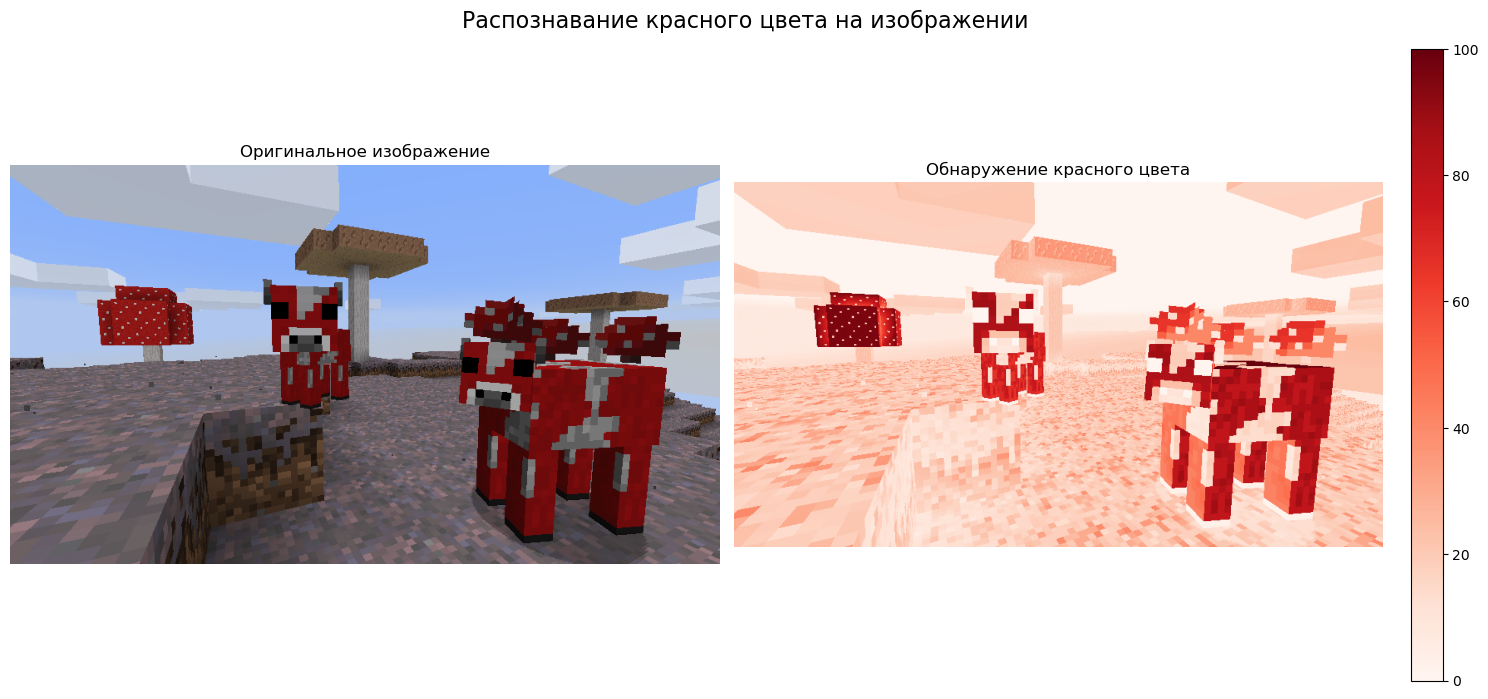

In [13]:
nn_rgb = NeuralNetwork(n_neurons=1, n_inputs=3)

x_train_norm = x_train / 255.0
y_train_norm = y_train.copy()

nn_rgb.fit(x_train_norm, y_train_norm, alpha=0.1, target_error=0.05)
        
result = process_image_for_red_detection(nn_rgb, "02_lab_data/mushroom_cow_minecraft.jpg")

Проверка работы `Image.fromarray()` для вывода результатов обучения

In [14]:
import numpy as np
from PIL import Image

var_1 = np.array([[255, 0, 255, 255, 255],
                  [100, 0, 100, 100, 100],
                  [0,   0, 0,   0,   0],
                  [100, 0, 100, 100, 100],
                  [0,   0, 0,   0,   0]], dtype='uint8')
var_2 = np.array([[[255,255,255],[0,0,0],[255,0,0],[0,255,0],[0,0,255]],
                  [[100,0,0],[0,0,0],[100,0,0],[100,0,0],[100,0,0]],
                  [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]],
                  [[100,0,0],[0,0,0],[100,0,0],[100,0,0],[100,0,0]],
                  [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]]], dtype='uint8')

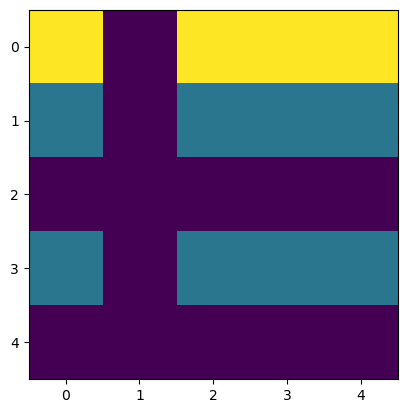

In [15]:
img1 = Image.fromarray(var_1)
img1.save("02_lab_data/grey_image.png")
plt.imshow(img1)

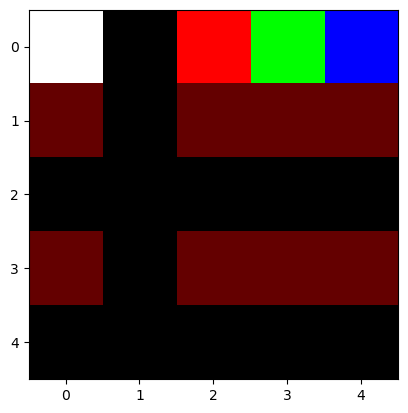

In [16]:
img2 = Image.fromarray(var_2)
img2.save("02_lab_data/color_image.png")
plt.imshow(img2)

Размер изображения: 5x5, Каналы: 3


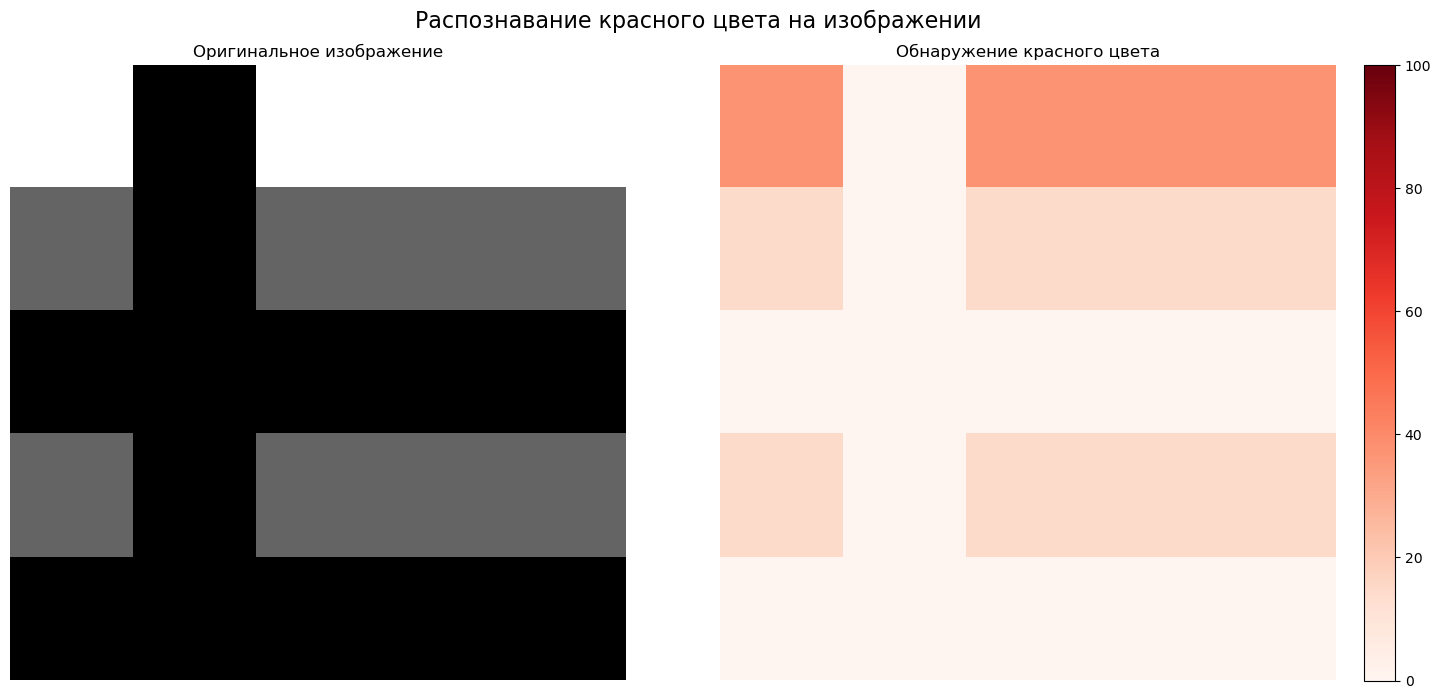

In [17]:
result = process_image_for_red_detection(nn_rgb, "02_lab_data/grey_image.png")

Размер изображения: 5x5, Каналы: 3


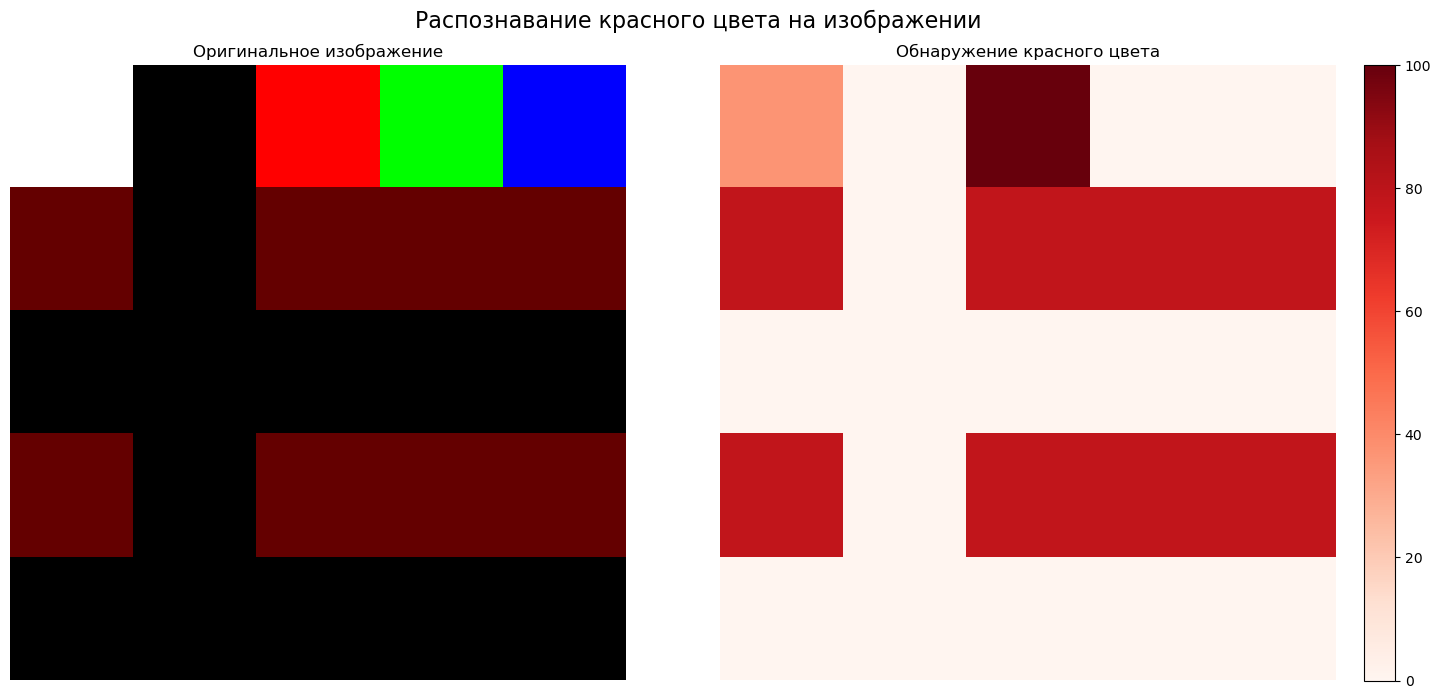

In [18]:
result = process_image_for_red_detection(nn_rgb, "02_lab_data/color_image.png")

# Работает с моделью машинного обучения:

> Тут была магия, которую вам надо реализовать.

In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression().fit(x_train, y_train)
model.score(x_test, y_test)

0.999

Подготовка данных (всего изображения) для передачи в нейронку.
Обработка данных нейронной сетью.

In [20]:
mas = a.reshape(480 * 854, 3)

res = 100 * model.predict(mas) 

Преобразование полученного от нейронки списка в массив для вывода на экран.

In [21]:
our_array = np.array(res, dtype='uint8').reshape(480, 854)

Проверка количества пикселей, распознанных как красные.

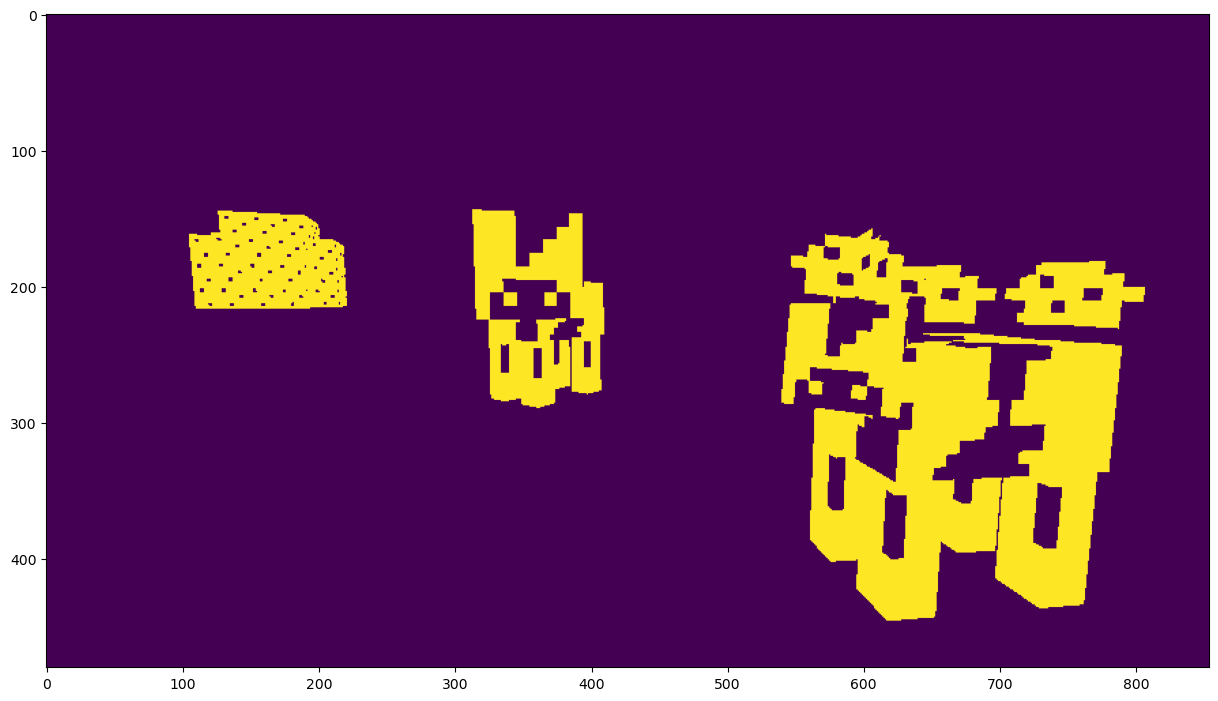

In [22]:
plt.figure(figsize=(15.,10.))
plt.imshow(Image.fromarray(our_array, mode="L"))